# Autoencodeur multimodal optimisé (version 4)

Ce notebook cherche **les meilleurs réglages possibles** de l'autoencodeur multimodal, sans tricher. Il reprend la lecture des données de la version 3 (cœur, peau, respiration, pupille, fenêtres décalées de 0 à 6 s) et ajoute :

| Ce qui est optimisé | Valeurs essayées |
| --- | --- |
| Signaux en entrée | cœur + peau ; cœur + peau + pupille ; les quatre |
| Décalage de chaque signal (alignement temporel) | cœur 0 à 2 s, peau 0 à 5 s, respiration 0 à 4 s, pupille 0 à 1 s |
| Architecture | largeur 8, 16 ou 32 ; 1 ou 2 couches cachées ; code de 1, 2, 4 ou 8 nombres ; activation tanh ou GELU |
| Régularisation | dropout ; bruit sur les entrées (autoencodeur débruiteur) ; **masquage de signaux** (on cache un signal, le code doit quand même tout reconstruire) ; weight decay |
| Règles de la perte | poids de la traduction, de la ressemblance des codes, et d'une petite **tête supervisée** (comme le « D » de la DCCA) |
| Apprentissage | taux d'apprentissage ; **arrêt anticipé** sur des participants de validation |
| Sonde | sur le code commun, ou sur les codes de chaque signal mis bout à bout |
| Stabilité | **ensemble** de 5 graines au moment final (moyenne des probabilités) |

**La règle qui rend le résultat honnête : la validation croisée imbriquée.**

- **Boucle extérieure** (comme avant) : un participant est mis de côté pour le test final.
- **Boucle intérieure** : sur les participants restants seulement, on compare tous les réglages candidats par une validation croisée par groupes de participants, et on garde le meilleur.
- Le participant de test ne sert **jamais** à choisir un réglage. Si on choisissait les réglages sur le score de test, le score serait gonflé et ne voudrait plus rien dire.

**Comparaison équitable :** une régression logistique simple reçoit le **même budget d'optimisation** (signaux, décalages, régularisation). Sinon, on ne saurait pas si le gain vient de l'autoencodeur ou juste de l'optimisation.

**Avant de lancer :** même installation que la v2 et la v3 (`torch` en plus). Tout tourne sur CPU. La recherche est la partie longue : régler `N_CONFIGS` et `N_JOBS` en section 5.

In [2]:
import json
import sys
import time
from copy import deepcopy
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyedflib
import torch
from IPython.display import display
from scipy.signal import butter, find_peaks, sosfiltfilt
from joblib import Parallel, delayed
from scipy.stats import wilcoxon
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from torch import nn

cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Lancer le noyau depuis la racine du repo ou depuis starting_notebooks/.")
if str(ROOT / "starting_notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import uV_to_uS

mne.set_log_level("ERROR")
torch.set_num_threads(1)

## 1 · Réglages et participants

`PARTICIPANT_IDS = None` utilise tous les participants téléchargés. Pour en ajouter, mettre `DOWNLOAD_N` à un nombre (par exemple 25) et lancer la cellule : elle choisit au hasard, avec une graine fixe, des participants qui ont au moins 20 notes d'arousal au jour 1, en excluant les participants de test et ceux déjà présents. Environ 220 Mo par participant. Remettre ensuite `DOWNLOAD_N = 0`.

In [3]:
DATA_ROOT = ROOT / "sample"
BDF_ROOT = DATA_ROOT / "PREPROCESSED"
TRIAL_S = 10.0          # fenêtre analysée après le début de la vidéo (s)
BASELINE_S = 2.0        # référence avant la vidéo (s)
MIN_TRIALS = 10         # bons essais minimum par participant
LAGS_S = (0, 1, 2, 3, 4, 5, 6)  # décalages testés pour l'alignement temporel (s)
PARTICIPANT_IDS = None  # None : tous les participants téléchargés
DOWNLOAD_N = 0          # >0 : télécharge ce nombre de participants en plus
DOWNLOAD_SEED = 42

labels_path = DATA_ROOT / "labels_train.csv"
if not labels_path.is_file():
    raise FileNotFoundError(f"Télécharger labels_train.csv dans {DATA_ROOT}.")
labels = pd.read_csv(labels_path, na_values=["TESTSUBJECT"], usecols=[
    "cohort", "participant_id", "day", "start_marker", "rating_arousal"])
labels["participant_id"] = labels["participant_id"].astype(str).str.strip()
labels["day"] = pd.to_numeric(labels["day"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
labels["start_marker"] = pd.to_numeric(labels["start_marker"], errors="coerce")
labels["rating_arousal"] = pd.to_numeric(labels["rating_arousal"], errors="coerce")
labels = labels.dropna(subset=["day", "start_marker"])
labels[["day", "start_marker"]] = labels[["day", "start_marker"]].astype(int)
keys = ["participant_id", "day", "start_marker"]
if labels.duplicated(keys).any():
    raise ValueError("Marqueurs ambigus dans labels_train.csv.")


def downloaded_ids():
    found = BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf")
    return {path.parent.name for path in found}


if DOWNLOAD_N > 0:
    from huggingface_hub import snapshot_download
    rated = labels[(labels.day == 1) & labels.rating_arousal.notna()]
    rated = rated[rated.participant_id.str.fullmatch(r"P\d+")]
    counts = rated.groupby("participant_id").size()
    candidates = sorted(set(counts[counts >= 20].index) - downloaded_ids())
    rng_download = np.random.default_rng(DOWNLOAD_SEED)
    chosen = sorted(rng_download.choice(candidates, size=min(DOWNLOAD_N, len(candidates)), replace=False))
    print(f"Téléchargement de {len(chosen)} participants (≈ {0.22 * len(chosen):.1f} Go) : {', '.join(chosen)}")
    patterns = []
    for p in chosen:
        stem = f"PREPROCESSED/{p}/{p}_day-1_task-emotion-video_multimodal"
        patterns += [f"{stem}.bdf", f"{stem}.record_map"]
    snapshot_download(repo_id="HABSteam/multimodal-eeg-emotion", repo_type="dataset",
                      local_dir=str(DATA_ROOT), allow_patterns=patterns)

available_bdfs = sorted(BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf"))
if PARTICIPANT_IDS is not None:
    by_id = {bdf.parent.name: bdf for bdf in available_bdfs}
    missing = sorted(set(PARTICIPANT_IDS) - set(by_id))
    if missing:
        raise FileNotFoundError(f"Fichiers manquants : {missing}")
    available_bdfs = [by_id[p] for p in PARTICIPANT_IDS]
bdfs = available_bdfs
if not bdfs:
    raise FileNotFoundError(f"Aucun fichier emotion-video du jour 1 dans {BDF_ROOT}.")

marker_key = pd.read_csv(ROOT / "starting_notebooks" / "markers.csv")
video_key = marker_key.loc[marker_key["Start Marker"] >= 10100].set_index("Start Marker")
end_marker = video_key["End Marker"].to_dict()

selected = [bdf.parent.name for bdf in bdfs]
cohorts = labels.loc[labels.participant_id.isin(selected)].groupby("participant_id").cohort.first()
print(f"{len(bdfs)} enregistrements sélectionnés : {', '.join(selected)}")
print("Participants par cohorte :", cohorts.value_counts().sort_index().to_dict())

26 enregistrements sélectionnés : P001, P017, P020, P026, P086, P090, P097, P124, P126, P128, P129, P131, P137, P138, P174, P186, P187, P189, P194, P201, P217, P219, P308, P310, P367, P459
Participants par cohorte : {1: 14, 2: 8, 3: 2, 4: 1, 5: 1}


## 2 · Lire les signaux et calculer les résumés

On lit seulement les canaux utiles, pour économiser la mémoire : cœur (`ECG`), peau (`GSR`), respiration (`Resp`) à 1 000 Hz, et pupille (`pupildiameter_le`, `pupildiameter_ri`) à environ 166 Hz. Les mesures de pupille sont placées sur l'horloge commune avec la même règle que `bdf_loader.py` (fréquence effective et décalage de départ du `.record_map`).

| Signal | Résumés (3 par signal) | Contrôle qualité |
| --- | --- | --- |
| Cœur | Fréquence médiane, variabilité des battements, changement entre la 2e et la 1re moitié (identiques au notebook d'origine) | Au moins 6 battements réalistes |
| Peau | Hausse moyenne après 2 s, hausse maximale, pente, par rapport aux 2 s d'avant (identiques au notebook d'origine) | Ni cassée, ni plate, ni bloquée aux bords |
| Respiration | Rythme (cycles par minute), amplitude (écart-type), changement de niveau par rapport aux 2 s d'avant | Au moins 2 cycles détectés, signal non plat |
| Pupille | Dilatation moyenne, dilatation maximale, pente, par rapport aux 2 s d'avant | Au moins 60 % de mesures valides (hors clignements) avant et pendant la vidéo |

La respiration est en unités arbitraires : seule sa variation compte, et la standardisation par participant (section 4) la rend comparable. La pupille dépend aussi de la luminosité des vidéos, qu'on ne connaît pas.

**Fenêtres décalées (pour l'alignement temporel).** Les mêmes résumés sont aussi calculés dans des fenêtres de 10 s qui commencent `τ` secondes après le début de la vidéo, pour chaque `τ` de `LAGS_S`. La référence (les 2 s avant la vidéo) ne bouge pas : seule la fenêtre de réponse glisse. Avec `τ = 0`, on retrouve exactement les résumés habituels. Les colonnes décalées s'appellent par exemple `gsr_mean_delta@3` (fenêtre de 3 à 13 s).

In [4]:
MODALITY_COLS = {
    "ECG": ["ecg_hr", "ecg_rr_sd", "ecg_hr_change"],
    "GSR": ["gsr_mean_delta", "gsr_max_delta", "gsr_slope"],
    "RESP": ["resp_rate", "resp_amp", "resp_level_delta"],
    "PUPIL": ["pup_mean_delta", "pup_max_delta", "pup_slope"],
}
PUPIL_VALID_MM = (1.5, 9.0)   # diamètres plausibles (mm) ; le reste = clignement ou perte
PUPIL_GRID_HZ = 50            # grille de rééchantillonnage de la pupille


def read_signals(bdf):
    # Lit cœur, peau, respiration (1 kHz) et pupille (temps et valeurs) d'un enregistrement.
    record_map = json.loads(bdf.with_suffix(".record_map").read_text(encoding="utf-8"))
    groups = [spec for stream in record_map["stream_map"].values() for spec in stream.values()]
    with pyedflib.EdfReader(str(bdf)) as reader:
        names = reader.getSignalLabels()
        for needed in ["ECG", "GSR", "Resp", "pupildiameter_le", "pupildiameter_ri"]:
            if needed not in names:
                raise ValueError(f"Canal {needed} absent de {bdf.name}.")
        ecg_id, gsr_id, resp_id = names.index("ECG"), names.index("GSR"), names.index("Resp")
        fs = reader.getSampleFrequency(ecg_id)
        n_samples = reader.getNSamples()
        total = record_map.get("TotalSamples")
        n_master = int(min(n_samples[ecg_id], total)) if isinstance(total, int) and total > 0 else int(n_samples[ecg_id])
        ecg = reader.readSignal(ecg_id, 0, n_master)
        gsr_uV = reader.readSignal(gsr_id, 0, n_master)
        resp = reader.readSignal(resp_id, 0, n_master)

        # Pupille : même alignement que bdf_loader.load_bdf.
        gaze = [g for g in groups if g.get("correction", {}).get("RecordType", "").lower() == "oculometry"][0]
        correction = gaze["correction"]
        gaze_rate = float(correction.get("EffectiveSamplingFrequency", correction.get("SamplingFrequency")))
        onset = float(correction.get("OnsetSeconds", 0.0))
        native_count = round(n_master * gaze_rate / fs)
        onset_idx = min(max(round(onset * fs), 0), n_master - 1)
        filler = round(onset * gaze_rate)
        rows = np.round(np.linspace(onset_idx, n_master - 1, native_count - filler)).astype(int)
        eyes = []
        for name in ["pupildiameter_le", "pupildiameter_ri"]:
            idx = names.index(name)
            packed = reader.readSignal(idx, 0, min(native_count, int(n_samples[idx])))
            packed = np.pad(packed, (0, native_count - len(packed)), constant_values=np.nan)[filler:]
            packed[(packed < PUPIL_VALID_MM[0]) | (packed > PUPIL_VALID_MM[1])] = np.nan
            eyes.append(packed)
    with np.errstate(all="ignore"):
        pupil = np.nanmean(np.vstack(eyes), axis=0)
    return {"fs": fs, "ecg": ecg, "gsr_uV": gsr_uV, "gsr_uS": uV_to_uS(gsr_uV), "resp": resp,
            "pupil_t": rows / fs, "pupil": pupil, "duration_s": n_master / fs}


def video_intervals(bdf):
    # Associe chaque début de vidéo à son marqueur de fin (identique au notebook d'origine).
    raw = mne.io.read_raw_bdf(bdf, preload=False, verbose="ERROR")
    events = pd.DataFrame({"time": raw.annotations.onset - raw.first_time,
                           "code": pd.to_numeric(raw.annotations.description, errors="coerce")}
                          ).dropna().reset_index(drop=True)
    raw.close()
    pairs = []
    for i in range(len(events) - 1):
        start, end = events.iloc[i], events.iloc[i + 1]
        marker = int(start.code)
        if marker in end_marker and end.code == end_marker[marker] and end.time > start.time:
            pairs.append((float(start.time), float(end.time), marker))
    return pairs

In [5]:
def detect_beats(ecg, fs):
    sos = butter(2, (5, 20), btype="bandpass", fs=fs, output="sos")
    width = max(1, round(0.08 * fs))
    envelope = np.convolve(np.abs(sosfiltfilt(sos, ecg)), np.ones(width) / width, mode="same")
    peaks, _ = find_peaks(envelope, distance=round(0.4 * fs), prominence=np.std(envelope))
    return peaks


def ecg_features(ecg, fs):
    peaks = detect_beats(ecg, fs)
    rr = np.diff(peaks) / fs
    plausible = (rr >= 0.4) & (rr <= 1.5)
    hr, beat_s = 60 / rr[plausible], peaks[1:][plausible] / fs
    late = beat_s >= TRIAL_S / 2
    if plausible.sum() < 6 or late.all() or not late.any():
        return None
    return {"ecg_hr": np.median(hr), "ecg_rr_sd": 1000 * np.std(rr[plausible]),
            "ecg_hr_change": hr[late].mean() - hr[~late].mean()}


def gsr_features(gsr, fs, lag=0.0):
    # gsr : de -BASELINE_S à +lag+TRIAL_S. Référence avant la vidéo, réponse dans la fenêtre décalée de lag.
    n_base = round(BASELINE_S * fs)
    response = gsr[n_base + round(lag * fs):] - gsr[:n_base].mean()
    seconds = np.arange(len(response)) / fs
    return {"gsr_mean_delta": response[seconds >= 2].mean(), "gsr_max_delta": response.max(),
            "gsr_slope": np.polyfit(seconds[::20], response[::20], 1)[0]}


def gsr_ok(gsr_uS, gsr_raw_window, floor, ceiling):
    if not np.isfinite(gsr_uS).all():
        return "GSR non-finite"
    if np.mean(np.diff(gsr_uS) == 0) > 0.5 or np.mean((gsr_raw_window <= floor) | (gsr_raw_window >= ceiling)) > 0.01:
        return "GSR flat or clipped"
    return None


def resp_features(resp, fs, lag=0.0):
    # resp : de -BASELINE_S à +lag+TRIAL_S. Rythme, amplitude et changement de niveau.
    if not np.isfinite(resp).all() or np.std(resp) == 0:
        return None
    sos = butter(2, (0.1, 1.0), btype="bandpass", fs=fs, output="sos")
    n_base = round(BASELINE_S * fs)
    start = n_base + round(lag * fs)
    window = sosfiltfilt(sos, resp)[start:]
    peaks, _ = find_peaks(window, distance=round(1.5 * fs), prominence=0.5 * np.std(window))
    if len(peaks) < 2:
        return None
    return {"resp_rate": 60 / np.median(np.diff(peaks) / fs),
            "resp_amp": np.std(window),
            "resp_level_delta": resp[start:].mean() - resp[:n_base].mean()}


def pupil_features(times, values, start_s, lag=0.0):
    # Référence de -BASELINE_S à 0, réponse de lag à lag+TRIAL_S, rééchantillonnées à PUPIL_GRID_HZ.
    lo, hi = np.searchsorted(times, [start_s - BASELINE_S - 0.5, start_s + lag + TRIAL_S + 0.5])
    t, v = times[lo:hi], values[lo:hi]
    ok = np.isfinite(v)
    base_grid = start_s + np.arange(-BASELINE_S, 0, 1 / PUPIL_GRID_HZ)
    grid = np.concatenate([base_grid, start_s + lag + np.arange(0, TRIAL_S, 1 / PUPIL_GRID_HZ)])
    base = np.arange(len(grid)) < len(base_grid)
    during = ~base
    # Part de mesures valides : un point de grille compte s'il a une vraie mesure à moins de 20 ms.
    if ok.sum() < 10:
        return None
    nearest = np.abs(t[ok][np.clip(np.searchsorted(t[ok], grid), 0, ok.sum() - 1)] - grid) < 0.02
    if nearest[base].mean() < 0.6 or nearest[during].mean() < 0.6:
        return None
    curve = np.interp(grid, t[ok], v[ok])
    response = curve[during] - curve[base].mean()
    seconds = grid[during] - (start_s + lag)
    return {"pup_mean_delta": response[seconds >= 0.5].mean(), "pup_max_delta": response.max(),
            "pup_slope": np.polyfit(seconds, response, 1)[0]}


def lag_cols(modality, lag):
    # Noms des colonnes d'un signal pour un décalage donné (sans suffixe pour lag = 0).
    return [c if lag == 0 else f"{c}@{lag}" for c in MODALITY_COLS[modality]]


def window_features(sig, start_s, lag, floor, ceiling):
    # Les 12 résumés dans la fenêtre [start+lag, start+lag+TRIAL_S], référence [start-BASELINE_S, start].
    fs = sig["fs"]
    first, onset = round((start_s - BASELINE_S) * fs), round((start_s + lag) * fs)
    last = round((start_s + lag + TRIAL_S) * fs)
    status, feats = {}, {}

    f = ecg_features(sig["ecg"][onset:onset + round(TRIAL_S * fs)], fs)
    status["ECG"] = "kept" if f else "too few ECG beats"
    feats.update(f or {})

    problem = gsr_ok(sig["gsr_uS"][first:last], sig["gsr_uV"][first:last], floor, ceiling)
    status["GSR"] = problem or "kept"
    if not problem:
        feats.update(gsr_features(sig["gsr_uS"][first:last], fs, lag))

    f = resp_features(sig["resp"][first:last], fs, lag)
    status["RESP"] = "kept" if f else "too few breaths or flat"
    feats.update(f or {})

    f = pupil_features(sig["pupil_t"], sig["pupil"], start_s, lag)
    status["PUPIL"] = "kept" if f else "too many invalid samples"
    feats.update(f or {})
    return status, feats

In [6]:
rows, log = [], []
for bdf in bdfs:
    participant = bdf.parent.name
    intervals = video_intervals(bdf)
    sig = read_signals(bdf)
    fs = sig["fs"]
    floor, ceiling = sig["gsr_uV"].min(), sig["gsr_uV"].max()
    for order, (start_s, end_s, marker) in enumerate(intervals):
        entry = {"participant_id": participant, "start_marker": marker}
        if end_s - start_s < TRIAL_S - 0.1:
            log.append({**entry, "ECG": "video shorter than 10 s", "GSR": "video shorter than 10 s",
                        "RESP": "video shorter than 10 s", "PUPIL": "video shorter than 10 s"})
            continue
        if start_s < BASELINE_S or start_s + TRIAL_S > sig["duration_s"]:
            log.append({**entry, "ECG": "window outside recording", "GSR": "window outside recording",
                        "RESP": "window outside recording", "PUPIL": "window outside recording"})
            continue
        status, feats = window_features(sig, start_s, 0, floor, ceiling)
        for lag in LAGS_S:
            if lag == 0 or start_s + lag + TRIAL_S > sig["duration_s"]:
                continue
            _, shifted = window_features(sig, start_s, lag, floor, ceiling)
            feats.update({f"{name}@{lag}": value for name, value in shifted.items()})

        log.append({**entry, **status})
        rows.append({"participant_id": participant, "day": 1, "start_marker": marker, "trial_order": order, **feats})
    del sig
    print(f"{participant} : {len(intervals)} vidéos lues")

log = pd.DataFrame(log)
all_cols = [c for cols in MODALITY_COLS.values() for c in cols]
all_lag_cols = [c for lag in LAGS_S if lag for m in MODALITY_COLS for c in lag_cols(m, lag)]
features = pd.DataFrame(rows).reindex(columns=keys + ["trial_order"] + all_cols + all_lag_cols)
trials_all = features.merge(labels.drop(columns="cohort"), on=keys, how="left", validate="one_to_one")
print(f"{len(log)} vidéos, {len(trials_all)} essais avec au moins une décision.")

C:\Users\HA\AppData\Local\Temp\ipykernel_5444\2015247952.py:46: RuntimeWarning: Mean of empty slice
  pupil = np.nanmean(np.vstack(eyes), axis=0)


P001 : 36 vidéos lues
P017 : 36 vidéos lues
P020 : 36 vidéos lues
P026 : 36 vidéos lues
P086 : 36 vidéos lues
P090 : 36 vidéos lues
P097 : 36 vidéos lues
P124 : 35 vidéos lues
P126 : 36 vidéos lues
P128 : 36 vidéos lues
P129 : 36 vidéos lues
P131 : 36 vidéos lues
P137 : 36 vidéos lues
P138 : 36 vidéos lues
P174 : 54 vidéos lues
P186 : 54 vidéos lues
P187 : 54 vidéos lues
P189 : 54 vidéos lues
P194 : 54 vidéos lues
P201 : 54 vidéos lues
P217 : 54 vidéos lues
P219 : 54 vidéos lues
P308 : 36 vidéos lues
P310 : 36 vidéos lues
P367 : 24 vidéos lues
P459 : 48 vidéos lues
1079 vidéos, 1008 essais avec au moins une décision.


## 3 · Contrôle qualité et choix des essais communs

Pour que **toutes les versions soient comparées sur exactement les mêmes essais**, on garde seulement les essais où **les quatre signaux** sont valides, **pour tous les décalages de `LAGS_S`** (sinon les versions alignées et non alignées ne verraient pas les mêmes vidéos), puis les participants qui en ont au moins `MIN_TRIALS`. Si la pupille ou la respiration font perdre trop d'essais, on peut retirer ce signal de `USED_MODALITIES` (par exemple `["ECG", "GSR", "RESP"]`) et relancer à partir d'ici.

In [7]:
USED_MODALITIES = ["ECG", "GSR", "RESP", "PUPIL"]

print("Essais valides par signal (proportion) :")
display(log[USED_MODALITIES].eq("kept").groupby(log.participant_id).mean().round(2))

used_cols = [c for m in USED_MODALITIES for c in MODALITY_COLS[m]]
used_lag_cols = [c for lag in LAGS_S if lag for m in USED_MODALITIES for c in lag_cols(m, lag)]
complete_0 = trials_all.dropna(subset=used_cols)
complete = complete_0.dropna(subset=used_lag_cols).copy()
print(f"Essais complets sans décalage : {len(complete_0)} ; complets pour tous les décalages : {len(complete)}.")
usable = complete.groupby("participant_id").size()
dropped = {p: int(usable.get(p, 0)) for p in selected if usable.get(p, 0) < MIN_TRIALS}
trials = complete.loc[~complete.participant_id.isin(dropped)].reset_index(drop=True)
retained = sorted(trials.participant_id.unique())
if dropped:
    print("Participants exclus (essais complets) :", dropped)
print(f"Gardés : {len(trials)} essais complets, {len(retained)} participants, "
      f"{trials.rating_arousal.notna().sum()} essais avec une note d'arousal.")
print("Participants retenus par cohorte :", cohorts.reindex(retained).value_counts().sort_index().to_dict())
if len(retained) < 3:
    raise RuntimeError("Il faut au moins 3 participants retenus.")

Essais valides par signal (proportion) :


,ECG,GSR,RESP,PUPIL
participant_id,,,,
P001,0.92,0.92,0.92,0.92
P017,0.94,0.94,0.89,0.94
P020,0.97,0.97,0.83,0.97
P026,0.97,0.00,0.75,0.97
P086,0.92,0.92,0.86,0.92
P090,0.97,0.25,0.78,0.97
P097,0.97,0.97,0.78,0.97
P124,0.97,0.00,0.97,0.97
P126,0.94,0.94,0.75,0.94


Essais complets sans décalage : 755 ; complets pour tous les décalages : 598.
Participants exclus (essais complets) : {'P026': 0, 'P090': 1, 'P124': 0, 'P138': 1, 'P189': 9, 'P367': 8}
Gardés : 579 essais complets, 20 participants, 505 essais avec une note d'arousal.
Participants retenus par cohorte : {1: 10, 2: 7, 3: 2, 4: 1}


## 4 · Standardiser et découper en plis

Comme avant : standardisation par participant, plis leave-one-participant-out, cible = arousal au-dessus de la médiane du participant. `XL[signal][décalage]` contient les résumés de chaque signal pour chaque fenêtre décalée.

In [8]:
z = trials.groupby("participant_id")[used_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=0)).fillna(0.0)
z_lag = trials.groupby("participant_id")[used_lag_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=0)).fillna(0.0)
X = {m: z[MODALITY_COLS[m]].to_numpy() for m in USED_MODALITIES}
XL = {m: {lag: (X[m] if lag == 0 else z_lag[lag_cols(m, lag)].to_numpy()) for lag in LAGS_S} for m in USED_MODALITIES}
x_all = np.column_stack([X[m] for m in USED_MODALITIES])

groups = trials.participant_id.to_numpy()
folds = list(LeaveOneGroupOut().split(x_all, groups=groups))
assert all(set(groups[tr]).isdisjoint(groups[te]) for tr, te in folds)

median_rating = trials.groupby("participant_id").rating_arousal.transform("median")
target = trials.rating_arousal.gt(median_rating).astype(float).where(trials.rating_arousal.notna()).to_numpy()
labelled = np.isfinite(target)
print(f"{len(folds)} plis, {labelled.sum()} essais notés.")

20 plis, 505 essais notés.


## 5 · L'autoencodeur réglable et l'espace de recherche

Un seul modèle, dont tous les réglages viennent d'un dictionnaire `cfg`. Avec les réglages `DEFAULT`, c'est exactement l'autoencodeur des versions précédentes.

**Les nouveautés du modèle :**

- **Bruit sur les entrées** (`input_noise`) : l'encodeur voit une version bruitée, le décodeur doit reconstruire la version propre. Le code apprend ce qui est stable plutôt que le bruit.
- **Masquage de signaux** (`modality_dropout`) : pendant l'apprentissage, on retire au hasard le code d'un ou plusieurs signaux du code commun (il en reste toujours au moins un). Le code commun doit quand même reconstruire tous les signaux : c'est une forme de traduction plus forte.
- **Tête supervisée** (`w_supervised`) : une petite régression logistique sur le code commun, apprise en même temps, sur les essais notés des participants d'apprentissage. Avec un poids > 0, la représentation n'est plus purement non supervisée : on le signale dans les résultats, et on donne aussi le meilleur réglage **sans** supervision.
- **Arrêt anticipé** : 20 % des participants d'apprentissage servent de validation ; on garde l'état du réseau où la perte (non supervisée) de validation était la plus basse.

**Réglages de la recherche :**

- `N_CONFIGS` : nombre de réglages candidats tirés au hasard (le réglage `DEFAULT` est toujours inclus). 40 est un bon compromis ; 16 pour un essai rapide.
- `K_INNER` : nombre de groupes dans la validation croisée intérieure.
- `N_JOBS` : nombre de cœurs utilisés (−1 = tous). En cas d'erreur avec le calcul parallèle, mettre `N_JOBS = 1`.

In [9]:
N_CONFIGS = 16
N_LINEAR_CONFIGS = 16
K_INNER = 2
FINAL_SEEDS = (0, 1, 2)
MAX_EPOCHS, CHECK_EVERY, PATIENCE, VAL_FRACTION = 200, 10, 5, 0.2
SEARCH_SEED = 2026
N_JOBS = 1

DEFAULT = {"modalities": ("ECG", "GSR"), "lag_ECG": 0, "lag_GSR": 0, "lag_RESP": 0, "lag_PUPIL": 0,
           "hidden": 8, "depth": 1, "latent": 2, "activation": "tanh", "dropout": 0.0, "input_noise": 0.0,
           "modality_dropout": 0.0, "w_translation": 1.0, "w_alignment": 1.0, "w_supervised": 0.0,
           "lr": 1e-2, "weight_decay": 1e-3, "probe_on": "shared"}

modality_options = [tuple(m for m in opt if m in USED_MODALITIES)
                    for opt in [("ECG", "GSR"), ("ECG", "GSR", "PUPIL"), ("ECG", "GSR", "RESP", "PUPIL")]]
SEARCH_SPACE = {
    "modalities": list(dict.fromkeys(opt for opt in modality_options if len(opt) >= 2)),
    "lag_ECG": [l for l in (0, 1, 2) if l in LAGS_S],
    "lag_GSR": [l for l in (0, 1, 2, 3, 4, 5) if l in LAGS_S],
    "lag_RESP": [l for l in (0, 2, 4) if l in LAGS_S],
    "lag_PUPIL": [l for l in (0, 1) if l in LAGS_S],
    "hidden": [8, 16, 32], "depth": [1, 2], "latent": [1, 2, 4, 8], "activation": ["tanh", "gelu"],
    "dropout": [0.0, 0.1, 0.3], "input_noise": [0.0, 0.1, 0.3], "modality_dropout": [0.0, 0.25, 0.5],
    "w_translation": [0.0, 0.5, 1.0, 2.0], "w_alignment": [0.0, 0.5, 1.0], "w_supervised": [0.0, 0.1, 0.3, 1.0],
    "lr": [3e-3, 1e-2, 3e-2], "weight_decay": [1e-4, 1e-3, 1e-2], "probe_on": ["shared", "all_codes"],
}
LINEAR_SPACE = {k: SEARCH_SPACE[k] for k in ["modalities", "lag_ECG", "lag_GSR", "lag_RESP", "lag_PUPIL"]}
LINEAR_SPACE["C"] = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]


def sample_configs(space, n, seed, first=None):
    rng_cfg = np.random.default_rng(seed)
    out = [first] if first is not None else []
    seen = {repr(sorted(c.items())) for c in out}
    while len(out) < n:
        cfg = {k: v[rng_cfg.integers(len(v))] for k, v in space.items()}
        key = repr(sorted(cfg.items()))
        if key not in seen:
            seen.add(key)
            out.append(cfg)
    return out


CANDIDATES = sample_configs(SEARCH_SPACE, N_CONFIGS, SEARCH_SEED, first=DEFAULT)
LINEAR_CANDIDATES = sample_configs(LINEAR_SPACE, N_LINEAR_CONFIGS, SEARCH_SEED,
                                   first={**{k: DEFAULT[k] for k in LINEAR_SPACE if k in DEFAULT}, "C": 1.0})
print(f"{len(CANDIDATES)} réglages d'autoencodeur et {len(LINEAR_CANDIDATES)} de régression logistique à comparer.")

16 réglages d'autoencodeur et 16 de régression logistique à comparer.


In [10]:
def mlp(n_in, n_out, cfg):
    act = nn.Tanh if cfg["activation"] == "tanh" else nn.GELU
    layers, width = [], n_in
    for _ in range(cfg["depth"]):
        layers += [nn.Linear(width, cfg["hidden"]), act()]
        if cfg["dropout"] > 0:
            layers.append(nn.Dropout(cfg["dropout"]))
        width = cfg["hidden"]
    layers.append(nn.Linear(width, n_out))
    return nn.Sequential(*layers)


class TunableAE(nn.Module):
    def __init__(self, sizes, cfg):
        super().__init__()
        self.cfg = cfg
        self.enc = nn.ModuleList([mlp(n, cfg["latent"], cfg) for n in sizes])
        self.dec = nn.ModuleList([mlp(cfg["latent"], n, cfg) for n in sizes])
        self.head = nn.Linear(cfg["latent"], 1)

    def loss(self, xs, y=None, lab=None, training=True):
        cfg, mse, k = self.cfg, nn.functional.mse_loss, len(xs)
        inputs = [x + cfg["input_noise"] * torch.randn_like(x) for x in xs] if training and cfg["input_noise"] > 0 else xs
        codes = [enc(x) for enc, x in zip(self.enc, inputs)]
        stacked = torch.stack(codes)                                   # signaux × essais × code
        if training and cfg["modality_dropout"] > 0 and k > 1:
            keep = (torch.rand(k, stacked.shape[1], 1) > cfg["modality_dropout"]).float()
            keep[torch.randint(k, (stacked.shape[1],)), torch.arange(stacked.shape[1]), 0] = 1.0  # au moins un signal
            shared = (stacked * keep).sum(0) / keep.sum(0)
        else:
            shared = stacked.mean(0)
        rec = sum(mse(d(shared), x) for d, x in zip(self.dec, xs)) / k
        tra = (sum(mse(self.dec[j](codes[i]), xs[j]) for i, j in permutations(range(k), 2)) / (k * (k - 1))
               if k > 1 else torch.zeros(()))
        ali = sum(mse(c, shared) for c in codes) / k
        unsup = rec + cfg["w_translation"] * tra + cfg["w_alignment"] * ali
        total = unsup
        if training and cfg["w_supervised"] > 0 and y is not None and len(y) > 1:
            logits = self.head(shared[lab]).squeeze(-1)
            total = total + cfg["w_supervised"] * nn.functional.binary_cross_entropy_with_logits(logits, y)
        return total, unsup

    @torch.no_grad()
    def features(self, xs):
        codes = [enc(x) for enc, x in zip(self.enc, xs)]
        if self.cfg["probe_on"] == "shared":
            return torch.stack(codes).mean(0).numpy()
        return torch.cat(codes, dim=1).numpy()


def config_arrays(cfg):
    return [XL[m][cfg[f"lag_{m}"]] for m in cfg["modalities"]]


def as_tensors(arrays, rows):
    return [torch.as_tensor(a[rows], dtype=torch.float32) for a in arrays]


def split_validation(rows, seed):
    # Met de côté VAL_FRACTION des participants de rows pour l'arrêt anticipé.
    people = np.unique(groups[rows])
    if len(people) < 4:
        return rows, None
    n_val = max(1, int(round(VAL_FRACTION * len(people))))
    val_people = np.random.default_rng(seed).choice(people, size=n_val, replace=False)
    is_val = np.isin(groups[rows], val_people)
    return rows[~is_val], rows[is_val]


def fit_tunable(cfg, rows, seed, max_epochs, val_rows=None):
    torch.manual_seed(seed)
    arrays = config_arrays(cfg)
    xs = as_tensors(arrays, rows)
    lab = torch.as_tensor(labelled[rows])
    y = torch.as_tensor(target[rows][labelled[rows]], dtype=torch.float32)
    model = TunableAE([x.shape[1] for x in xs], cfg)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    xv = as_tensors(arrays, val_rows) if val_rows is not None else None
    best, best_state, bad = np.inf, None, 0
    for epoch in range(max_epochs):
        model.train()
        opt.zero_grad()
        total, _ = model.loss(xs, y, lab, training=True)
        total.backward()
        opt.step()
        if xv is not None and (epoch + 1) % CHECK_EVERY == 0:
            model.eval()
            with torch.no_grad():
                val = float(model.loss(xv, training=False)[1])
            if val < best - 1e-4:
                best, best_state, bad = val, deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model.eval()


def mean_auc(y, p, g):
    # AUC calculée participant par participant, puis moyennée (comme la boucle extérieure).
    vals = [roc_auc_score(y[g == q], p[g == q]) for q in np.unique(g) if len(set(y[g == q])) == 2]
    return float(np.mean(vals)) if vals else np.nan


def evaluate_ae(cfg, fit_rows, eval_rows, seeds, early=True, max_epochs=MAX_EPOCHS):
    # Apprend l'autoencodeur sur fit_rows, la sonde sur les essais notés de fit_rows, note eval_rows.
    torch.set_num_threads(1)
    tr, te = fit_rows[labelled[fit_rows]], eval_rows[labelled[eval_rows]]
    if len(te) < 5 or len(set(target[tr])) < 2 or len(set(target[te])) < 2:
        return np.nan, np.nan
    arrays, probs = config_arrays(cfg), []
    for s in seeds:
        if early:
            fit, val = split_validation(fit_rows, s)
            model = fit_tunable(cfg, fit, s, max_epochs, val)
        else:
            model = fit_tunable(cfg, fit_rows, s, max_epochs)
        probe = LogisticRegression(class_weight="balanced", max_iter=1000)
        probe.fit(model.features(as_tensors(arrays, tr)), target[tr])
        probs.append(probe.predict_proba(model.features(as_tensors(arrays, te)))[:, 1])
    p = np.mean(probs, axis=0)
    return balanced_accuracy_score(target[te], p > 0.5), mean_auc(target[te], p, groups[te])


def evaluate_linear(cfg, fit_rows, eval_rows):
    tr, te = fit_rows[labelled[fit_rows]], eval_rows[labelled[eval_rows]]
    if len(te) < 5 or len(set(target[tr])) < 2 or len(set(target[te])) < 2:
        return np.nan, np.nan
    feats = np.column_stack(config_arrays(cfg))
    model = LogisticRegression(C=cfg["C"], class_weight="balanced", max_iter=2000).fit(feats[tr], target[tr])
    p = model.predict_proba(feats[te])[:, 1]
    return balanced_accuracy_score(target[te], p > 0.5), mean_auc(target[te], p, groups[te])


def inner_score(kind, cfg, train):
    # AUC moyenne en validation croisée intérieure, sur les participants d'apprentissage seulement.
    torch.set_num_threads(1)
    aucs = []
    for a, b in GroupKFold(n_splits=min(K_INNER, len(np.unique(groups[train])))).split(train, groups=groups[train]):
        if kind == "ae":
            aucs.append(evaluate_ae(cfg, train[a], train[b], seeds=(0,), early=True)[1])
        else:
            aucs.append(evaluate_linear(cfg, train[a], train[b])[1])
    return float(np.nanmean(aucs)) if np.isfinite(aucs).any() else np.nan


# Vérification : avec DEFAULT et 200 époques, le modèle a la même forme que l'autoencodeur de la v2.
print(TunableAE([3, 3], DEFAULT))

TunableAE(
  (enc): ModuleList(
    (0-1): 2 x Sequential(
      (0): Linear(in_features=3, out_features=8, bias=True)
      (1): Tanh()
      (2): Linear(in_features=8, out_features=2, bias=True)
    )
  )
  (dec): ModuleList(
    (0-1): 2 x Sequential(
      (0): Linear(in_features=2, out_features=8, bias=True)
      (1): Tanh()
      (2): Linear(in_features=8, out_features=3, bias=True)
    )
  )
  (head): Linear(in_features=2, out_features=1, bias=True)
)


## 6 · La recherche imbriquée

Pour chaque pli extérieur :

1. chaque réglage candidat reçoit une **note intérieure** (AUC moyenne en validation croisée sur les participants d'apprentissage) ;
2. on garde **trois gagnants** : le meilleur autoencodeur toutes règles confondues, le meilleur autoencodeur **sans tête supervisée** (représentation purement non supervisée), et la meilleure régression logistique ;
3. chaque gagnant est réappris sur tous les participants d'apprentissage (ensemble de `FINAL_SEEDS` graines pour l'autoencodeur) et noté sur le participant de test.

On note aussi l'autoencodeur **à réglages fixes** de la v2 (`DEFAULT`, 200 époques, 3 graines), et deux repères simples : la classe majoritaire et la concaténation de tous les signaux.

C'est la cellule longue. Le temps estimé s'affiche après le premier pli.

In [11]:
inner_ae = np.full((len(folds), len(CANDIDATES)), np.nan)
inner_lin = np.full((len(folds), len(LINEAR_CANDIDATES)), np.nan)
is_supervised = np.array([c["w_supervised"] > 0 for c in CANDIDATES])
results, chosen = [], []
start = time.time()


def run_parallel(kind, configs, train):
    jobs = (delayed(inner_score)(kind, cfg, train) for cfg in configs)
    try:
        return Parallel(n_jobs=N_JOBS)(jobs)
    except Exception as error:  # repli sans calcul parallèle
        print("Calcul parallèle impossible, passage sur un seul cœur :", type(error).__name__)
        return [inner_score(kind, cfg, train) for cfg in configs]


for k, (train, test) in enumerate(folds):
    participant = groups[test][0]
    inner_ae[k] = run_parallel("ae", CANDIDATES, train)
    inner_lin[k] = run_parallel("linear", LINEAR_CANDIDATES, train)

    best_all = int(np.nanargmax(inner_ae[k]))
    best_unsup = int(np.nanargmax(np.where(is_supervised, -np.inf, inner_ae[k])))
    best_lin = int(np.nanargmax(inner_lin[k]))

    def record(version, ba, auc, idx=None, inner=None):
        results.append({"participant": participant, "version": version, "balanced accuracy": ba, "AUC": auc,
                        "réglage": idx, "AUC intérieure": inner})

    tr, te = train[labelled[train]], test[labelled[test]]
    if len(te) >= 5 and len(set(target[te])) == 2:
        dummy = DummyClassifier(strategy="most_frequent").fit(x_all[tr], target[tr])
        record("Classe majoritaire", balanced_accuracy_score(target[te], dummy.predict(x_all[te])), 0.5)
        record("Concaténation tous signaux (C = 1)",
               *evaluate_linear({**{f"lag_{m}": 0 for m in USED_MODALITIES}, "modalities": tuple(USED_MODALITIES),
                                 "C": 1.0}, train, test))
        record("AE réglages fixes (v2)", *evaluate_ae(DEFAULT, train, test, seeds=(0, 1, 2), early=False, max_epochs=200))
        record("Régression logistique optimisée", *evaluate_linear(LINEAR_CANDIDATES[best_lin], train, test),
               best_lin, inner_lin[k, best_lin])
        record("AE optimisé · non supervisé", *evaluate_ae(CANDIDATES[best_unsup], train, test, FINAL_SEEDS),
               best_unsup, inner_ae[k, best_unsup])
        if best_all == best_unsup:
            last = dict(results[-1]); last["version"] = "AE optimisé · tout réglage"; results.append(last)
        else:
            record("AE optimisé · tout réglage", *evaluate_ae(CANDIDATES[best_all], train, test, FINAL_SEEDS),
                   best_all, inner_ae[k, best_all])
    chosen.append({"participant": participant, "tout réglage": best_all, "non supervisé": best_unsup,
                   "régression logistique": best_lin})
    elapsed = time.time() - start
    print(f"pli {k + 1}/{len(folds)} ({participant}) · réglages choisis : AE {best_all}, AE non sup. {best_unsup}, "
          f"logistique {best_lin} · {elapsed / 60:.1f} min écoulées, "
          f"≈ {elapsed / (k + 1) * (len(folds) - k - 1) / 60:.0f} min restantes")

results, chosen = pd.DataFrame(results), pd.DataFrame(chosen)

pli 1/20 (P001) · réglages choisis : AE 5, AE non sup. 5, logistique 3 · 1.2 min écoulées, ≈ 23 min restantes
pli 2/20 (P017) · réglages choisis : AE 5, AE non sup. 5, logistique 3 · 2.3 min écoulées, ≈ 21 min restantes
pli 3/20 (P020) · réglages choisis : AE 10, AE non sup. 5, logistique 3 · 3.5 min écoulées, ≈ 20 min restantes
pli 4/20 (P086) · réglages choisis : AE 13, AE non sup. 5, logistique 3 · 4.8 min écoulées, ≈ 19 min restantes
pli 5/20 (P097) · réglages choisis : AE 14, AE non sup. 5, logistique 3 · 6.2 min écoulées, ≈ 19 min restantes
pli 6/20 (P126) · réglages choisis : AE 14, AE non sup. 5, logistique 14 · 7.7 min écoulées, ≈ 18 min restantes
pli 7/20 (P128) · réglages choisis : AE 14, AE non sup. 9, logistique 14 · 9.0 min écoulées, ≈ 17 min restantes
pli 8/20 (P129) · réglages choisis : AE 15, AE non sup. 5, logistique 9 · 10.2 min écoulées, ≈ 15 min restantes
pli 9/20 (P131) · réglages choisis : AE 5, AE non sup. 5, logistique 3 · 11.4 min écoulées, ≈ 14 min restantes


## 7 · Résultats sur les participants jamais vus

Même lecture que d'habitude : **0,50 = hasard**. La question principale est la ligne « AE optimisé · non supervisé » contre « AE réglages fixes (v2) » (l'optimisation aide-t-elle ?) et contre « Régression logistique optimisée » (l'autoencodeur fait-il mieux qu'un modèle simple optimisé avec le même budget ?).

balanced accuracy           AUC         \
                                                mean    std   mean    std   
version                                                                     
Classe majoritaire                             0.500  0.000  0.500  0.000   
Concaténation tous signaux (C = 1)             0.559  0.082  0.594  0.104   
Régression logistique optimisée                0.541  0.096  0.551  0.112   
AE réglages fixes (v2)                         0.563  0.085  0.565  0.115   
AE optimisé · non supervisé                    0.543  0.076  0.576  0.093   
AE optimisé · tout réglage                     0.514  0.092  0.565  0.102   

                                   participants  
                                              n  
version                                          
Classe majoritaire                           20  
Concaténation tous signaux (C = 1)           20  
Régression logistique optimisée              20  
AE réglages fixes (v2)                       20  
AE optimisé · non supervisé                  20  
AE optimisé · tout réglage                   20

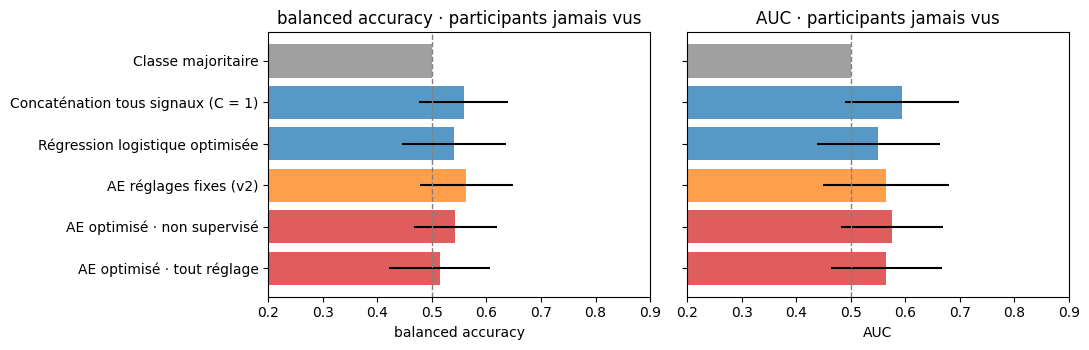

,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,AE optimisé · non supervisé,AE réglages fixes (v2),7 / 20,0.011,-0.042,0.070,0.898
1,AE optimisé · non supervisé,Régression logistique optimisée,12 / 20,0.025,-0.033,0.082,0.370
2,AE optimisé · tout réglage,AE optimisé · non supervisé,6 / 20,-0.011,-0.047,0.021,0.683
3,Régression logistique optimisée,Concaténation tous signaux (C = 1),5 / 20,-0.043,-0.079,-0.006,0.033
4,AE optimisé · non supervisé,Concaténation tous signaux (C = 1),6 / 20,-0.018,-0.079,0.048,0.277


In [12]:
ORDER = ["Classe majoritaire", "Concaténation tous signaux (C = 1)", "Régression logistique optimisée",
         "AE réglages fixes (v2)", "AE optimisé · non supervisé", "AE optimisé · tout réglage"]
summary = results.groupby("version")[["balanced accuracy", "AUC"]].agg(["mean", "std"]).reindex(ORDER)
summary[("participants", "n")] = results.groupby("version").size().reindex(ORDER)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, metric in zip(axes, ["balanced accuracy", "AUC"]):
    ax.barh(ORDER, summary[(metric, "mean")], xerr=summary[(metric, "std")],
            color=["gray", "tab:blue", "tab:blue", "tab:orange", "tab:red", "tab:red"], alpha=0.75)
    ax.axvline(0.5, color="gray", ls="--", lw=1)
    ax.set(xlabel=metric, xlim=(0.2, 0.9), title=f"{metric} · participants jamais vus")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()


def paired_table(table, pairs, metric, n_boot=5000, seed=0):
    wide = table.pivot(index="participant", columns="version", values=metric)
    rng_b = np.random.default_rng(seed)
    out = []
    for a, b in pairs:
        d = (wide[a] - wide[b]).dropna().to_numpy()
        boot = [rng_b.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
        p = wilcoxon(d).pvalue if np.any(d != 0) and len(d) >= 5 else np.nan
        out.append({"A": a, "B": b, "victoires de A": f"{int((d > 0).sum())} / {len(d)}",
                    "différence moyenne": d.mean(), "IC 95 % bas": np.percentile(boot, 2.5),
                    "IC 95 % haut": np.percentile(boot, 97.5), "p (Wilcoxon)": p})
    return pd.DataFrame(out).round(3)


METRIC = "AUC"
display(paired_table(results, [
    ("AE optimisé · non supervisé", "AE réglages fixes (v2)"),
    ("AE optimisé · non supervisé", "Régression logistique optimisée"),
    ("AE optimisé · tout réglage", "AE optimisé · non supervisé"),
    ("Régression logistique optimisée", "Concaténation tous signaux (C = 1)"),
    ("AE optimisé · non supervisé", "Concaténation tous signaux (C = 1)"),
], METRIC))

## 8 · Quels réglages gagnent ?

- **Tableau 1** : pour chaque réglage, combien de fois il a été choisi (sur tous les plis). Si le gagnant change à chaque pli, aucun réglage n'est nettement meilleur : les différences entre réglages sont surtout du bruit.
- **Tableau 2** : pour chaque valeur de chaque réglage, l'AUC intérieure moyenne des candidats qui l'utilisent. C'est une mesure simple de ce qui compte (par exemple : les décalages de la peau aident-ils ? le masquage de signaux aide-t-il ?).
- **Optimisme** : l'AUC intérieure du gagnant est toujours un peu trop flatteuse (on a choisi le meilleur parmi beaucoup). L'écart avec l'AUC de test mesure cet optimisme.

In [13]:
cfg_table = pd.DataFrame(CANDIDATES)
cfg_table["modalities"] = cfg_table["modalities"].map(lambda t: "+".join(t))
cfg_table["AUC intérieure moyenne"] = np.nanmean(inner_ae, axis=0)
cfg_table["choisi (tout réglage)"] = chosen["tout réglage"].value_counts().reindex(cfg_table.index, fill_value=0)
cfg_table["choisi (non supervisé)"] = chosen["non supervisé"].value_counts().reindex(cfg_table.index, fill_value=0)
print("Tableau 1 · les 10 réglages d'autoencodeur les mieux notés en moyenne (0 = DEFAULT)")
display(cfg_table.sort_values("AUC intérieure moyenne", ascending=False).head(10).round(3))

rows_imp = []
long = cfg_table.drop(columns=["choisi (tout réglage)", "choisi (non supervisé)"])
for param in SEARCH_SPACE:
    for value, group in long.groupby(param)["AUC intérieure moyenne"]:
        rows_imp.append({"réglage": param, "valeur": value, "AUC intérieure moyenne": group.mean(), "candidats": len(group)})
importance = pd.DataFrame(rows_imp)
spread = importance.groupby("réglage")["AUC intérieure moyenne"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
print("Tableau 2 · écart d'AUC intérieure entre la meilleure et la pire valeur de chaque réglage")
display(spread.round(3).to_frame("écart"))
display(importance.set_index(["réglage", "valeur"]).loc[spread.index[:6]].round(3))

opt = results.dropna(subset=["AUC intérieure"]).groupby("version")[["AUC intérieure", "AUC"]].mean()
opt["optimisme"] = opt["AUC intérieure"] - opt["AUC"]
print("Optimisme du choix (AUC intérieure du gagnant − AUC sur le participant testé)")
display(opt.round(3))

Tableau 1 · les 10 réglages d'autoencodeur les mieux notés en moyenne (0 = DEFAULT)


,modalities,lag_ECG,lag_GSR,lag_RESP,lag_PUPIL,hidden,depth,latent,activation,dropout,...,modality_dropout,w_translation,w_alignment,w_supervised,lr,weight_decay,probe_on,AUC intérieure moyenne,choisi (tout réglage),choisi (non supervisé)
5,ECG+GSR+RESP+PUPIL,1,3,2,0,32,1,2,tanh,0.3,...,0.00,0.0,0.0,0.0,0.030,0.001,shared,0.571,5,16
13,ECG+GSR+PUPIL,1,5,0,0,16,2,2,gelu,0.3,...,0.00,0.5,0.0,0.1,0.003,0.001,shared,0.570,4,0
14,ECG+GSR+RESP+PUPIL,1,2,0,1,16,2,4,gelu,0.3,...,0.25,2.0,0.0,1.0,0.003,0.000,shared,0.568,5,0
12,ECG+GSR+RESP+PUPIL,1,4,4,0,8,2,4,tanh,0.1,...,0.50,0.5,0.0,0.1,0.010,0.001,all_codes,0.561,0,0
15,ECG+GSR+PUPIL,1,1,4,0,16,1,4,tanh,0.3,...,0.50,1.0,1.0,0.1,0.030,0.000,shared,0.559,1,0
8,ECG+GSR,0,1,4,0,32,1,1,tanh,0.1,...,0.50,1.0,0.0,0.1,0.010,0.001,shared,0.558,1,0
6,ECG+GSR+PUPIL,1,2,2,1,8,1,4,gelu,0.1,...,0.25,0.0,0.5,0.1,0.010,0.010,shared,0.558,1,0
0,ECG+GSR,0,0,0,0,8,1,2,tanh,0.0,...,0.00,1.0,1.0,0.0,0.010,0.001,shared,0.546,1,2
9,ECG+GSR,2,3,4,1,32,2,4,tanh,0.0,...,0.50,0.5,0.0,0.0,0.003,0.010,shared,0.544,0,2
1,ECG+GSR+RESP+PUPIL,0,0,2,0,16,1,2,gelu,0.1,...,0.50,1.0,1.0,0.3,0.003,0.010,all_codes,0.540,0,0


Tableau 2 · écart d'AUC intérieure entre la meilleure et la pire valeur de chaque réglage


,écart
réglage,
lag_GSR,0.039
w_alignment,0.036
input_noise,0.029
latent,0.024
dropout,0.023
w_translation,0.022
weight_decay,0.022
w_supervised,0.021
modality_dropout,0.019


AUC intérieure moyenne  candidats
réglage       valeur                                   
lag_GSR       0                        0.531          6
              1                        0.539          4
              2                        0.563          2
              3                        0.558          2
              4                        0.561          1
              5                        0.570          1
w_alignment   0                        0.562          6
              0.5                      0.526          6
              1                        0.545          4
input_noise   0                        0.536          6
              0.1                      0.565          2
              0.3                      0.546          8
latent        1                        0.530          3
              2                        0.544          6
              4                        0.555          6
              8                        0.533          1
dropout       0                        0.529          3
              0.1                      0.545          7
              0.3                      0.552          6
w_translation 0                        0.554          3
              0.5                      0.554          4
              1                        0.539          7
              2                        0.532          2

Optimisme du choix (AUC intérieure du gagnant − AUC sur le participant testé)


,AUC intérieure,AUC,optimisme
version,,,
AE optimisé · non supervisé,0.575,0.576,-0.001
AE optimisé · tout réglage,0.587,0.565,0.022
Régression logistique optimisée,0.579,0.551,0.029


### Le réglage recommandé

Le candidat avec la meilleure AUC intérieure **moyenne sur tous les plis** est enregistré dans `best_autoencoder_config.json`, pour que l'équipe puisse le réutiliser. Attention : son score de référence est celui de la section 7 (« AE optimisé »), pas son AUC intérieure, qui est optimiste.

In [14]:
best_unsup_overall = int(np.nanargmax(np.where(is_supervised, -np.inf, np.nanmean(inner_ae, axis=0))))
best_overall = int(np.nanargmax(np.nanmean(inner_ae, axis=0)))
export = {"non supervisé": {**CANDIDATES[best_unsup_overall], "modalities": list(CANDIDATES[best_unsup_overall]["modalities"])},
          "tout réglage": {**CANDIDATES[best_overall], "modalities": list(CANDIDATES[best_overall]["modalities"])},
          "AUC test (section 7)": {v: round(float(summary.loc[v, ("AUC", "mean")]), 3)
                                    for v in ["AE optimisé · non supervisé", "AE optimisé · tout réglage"]}}
(Path.cwd() / "best_autoencoder_config.json").write_text(json.dumps(export, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(export, indent=2, ensure_ascii=False))

{
  "non supervisé": {
    "modalities": [
      "ECG",
      "GSR",
      "RESP",
      "PUPIL"
    ],
    "lag_ECG": 1,
    "lag_GSR": 3,
    "lag_RESP": 2,
    "lag_PUPIL": 0,
    "hidden": 32,
    "depth": 1,
    "latent": 2,
    "activation": "tanh",
    "dropout": 0.3,
    "input_noise": 0.1,
    "modality_dropout": 0.0,
    "w_translation": 0.0,
    "w_alignment": 0.0,
    "w_supervised": 0.0,
    "lr": 0.03,
    "weight_decay": 0.001,
    "probe_on": "shared"
  },
  "tout réglage": {
    "modalities": [
      "ECG",
      "GSR",
      "RESP",
      "PUPIL"
    ],
    "lag_ECG": 1,
    "lag_GSR": 3,
    "lag_RESP": 2,
    "lag_PUPIL": 0,
    "hidden": 32,
    "depth": 1,
    "latent": 2,
    "activation": "tanh",
    "dropout": 0.3,
    "input_noise": 0.1,
    "modality_dropout": 0.0,
    "w_translation": 0.0,
    "w_alignment": 0.0,
    "w_supervised": 0.0,
    "lr": 0.03,
    "weight_decay": 0.001,
    "probe_on": "shared"
  },
  "AUC test (section 7)": {
    "AE optimisé · no

code de 1 : fait (2.0 min)
code de 2 : fait (3.9 min)
code de 4 : fait (5.9 min)
code de 8 : fait (7.9 min)
code de 12 : fait (10.2 min)


,mean,std
taille du code,,
1,0.516,0.146
2,0.587,0.100
4,0.574,0.093
8,0.540,0.094
12,0.553,0.107


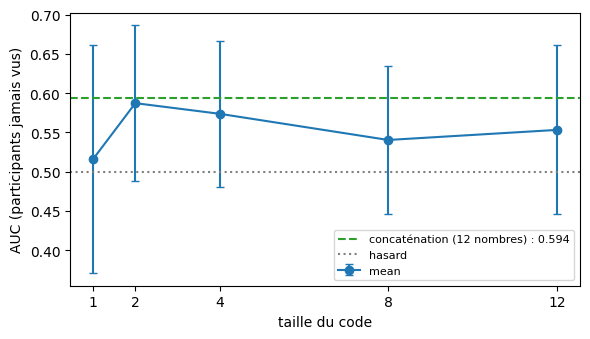

code 1 vs code 2 : différence -0.071, gagne sur 8 / 20, p = 0.123
code 4 vs code 2 : différence -0.014, gagne sur 6 / 20, p = 0.043
code 8 vs code 2 : différence -0.047, gagne sur 4 / 20, p = 0.011
code 12 vs code 2 : différence -0.034, gagne sur 10 / 20, p = 0.189


In [15]:
# Taille du code : le réglage n° 5, en ne changeant que le nombre de dimensions du code.
LATENT_SIZES = [1, 2, 4, 8, 12]
base = CANDIDATES[5]  # le meilleur autoencodeur non supervisé

rows_latent = []
start = time.time()
for latent in LATENT_SIZES:
    cfg = {**base, "latent": latent}
    for train, test in folds:
        ba, auc = evaluate_ae(cfg, train, test, seeds=(0, 1, 2))
        if np.isfinite(auc):
            rows_latent.append({"participant": groups[test][0], "taille du code": latent, "AUC": auc})
    print(f"code de {latent} : fait ({(time.time() - start) / 60:.1f} min)")

latent_scores = pd.DataFrame(rows_latent)
summary_latent = latent_scores.groupby("taille du code").AUC.agg(["mean", "std"])
reference = results[results.version == "Concaténation tous signaux (C = 1)"].AUC.mean()
display(summary_latent.round(3))

ax = summary_latent["mean"].plot(marker="o", yerr=summary_latent["std"], capsize=3, figsize=(6, 3.5))
ax.axhline(reference, color="tab:green", ls="--", label=f"concaténation (12 nombres) : {reference:.3f}")
ax.axhline(0.5, color="gray", ls=":", label="hasard")
ax.set(xlabel="taille du code", ylabel="AUC (participants jamais vus)", xticks=LATENT_SIZES)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

wide = latent_scores.pivot(index="participant", columns="taille du code", values="AUC")
for latent in LATENT_SIZES:
    if latent != 2:
        d = wide[latent] - wide[2]
        print(f"code {latent} vs code 2 : différence {d.mean():+.3f}, gagne sur {(d > 0).sum()} / {len(d)}, "
              f"p = {wilcoxon(d).pvalue:.3f}")

## 9 · Comment lire les résultats

**Les questions :**

1. **L'optimisation aide-t-elle ?** « AE optimisé · non supervisé » contre « AE réglages fixes (v2) ».
2. **L'autoencodeur bat-il un modèle simple qui a reçu le même effort ?** « AE optimisé · non supervisé » contre « Régression logistique optimisée ». Si la régression logistique fait aussi bien, l'avantage vient des entrées (signaux, décalages), pas de l'autoencodeur.
3. **La supervision aide-t-elle ?** « tout réglage » contre « non supervisé ». Si oui, c'est intéressant, mais ce n'est plus de l'apprentissage de représentation non supervisé : le dire clairement.
4. **Qu'est-ce qui compte vraiment ?** Section 8, tableau 2 : les réglages avec le plus grand écart.

**Pourquoi le résultat est honnête :** chaque score de la section 7 vient d'un participant qui n'a servi ni à apprendre le réseau, ni à choisir ses réglages.

**Limites :**

- Avec une trentaine de participants, les notes intérieures sont bruitées : le gagnant peut changer d'un pli à l'autre. C'est normal, et c'est ce que mesure le tableau 1.
- La recherche aléatoire n'essaie qu'une partie des combinaisons possibles. Augmenter `N_CONFIGS` explore plus, mais rend aussi le choix plus optimiste.
- La standardisation et la cible utilisent toutes les vidéos du participant testé (sans leurs notes), comme dans les versions précédentes.
- Les mêmes vidéos reviennent chez plusieurs participants : un modèle peut en partie reconnaître la vidéo plutôt que la réaction.